# Models: patterns, prediction, and crowds
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KatherineElkins/programminghumanity2026/blob/main/models_patterns_nov03_2026.ipynb)

Run setup, then any section. Change one setting at a time. All data are synthetic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Ready — no installs or uploads needed.')


Ready — no installs or uploads needed.


## 1. Different processes, different patterns
**Add** independent contributions → approximately normal. **Multiply** positive factors → approximately lognormal, under suitable conditions. A **power law** has a different tail; skew alone does not identify it.

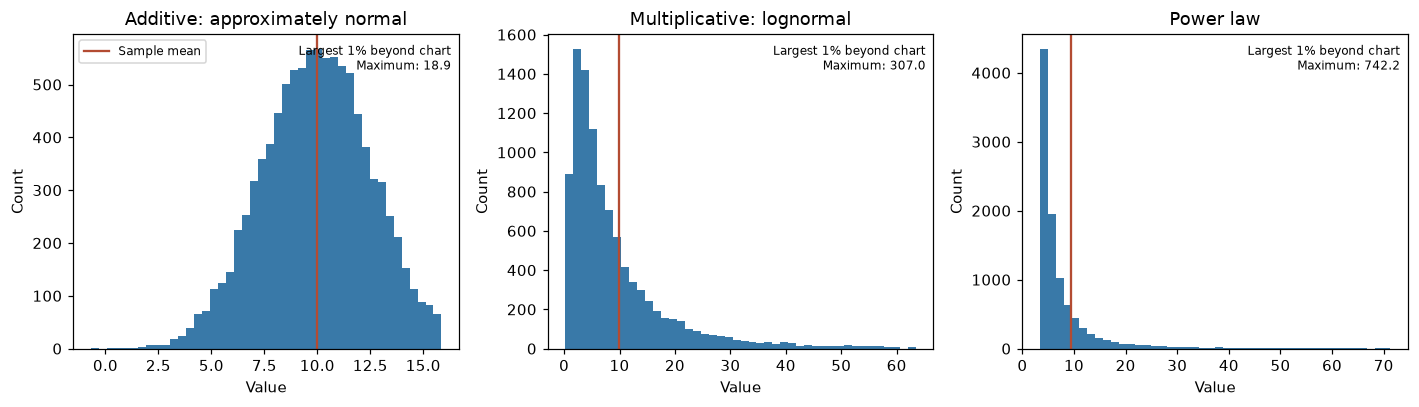

In [2]:
seed = 42
sample_size = 10000
power_exponent = 2.5  # Density exponent; must be greater than 2 here for a finite mean.
if sample_size < 100 or power_exponent <= 2:
    raise ValueError('Use at least 100 samples and an exponent greater than 2.')
rng = np.random.default_rng(seed)
# Each distribution has theoretical mean 10. Their tails differ.
normal = 10 + rng.uniform(-1, 1, (sample_size, 20)).sum(axis=1)
lognormal = 10 * np.exp(rng.normal(-0.5 / 20, 1 / np.sqrt(20), (sample_size, 20)).sum(axis=1))
shape = power_exponent - 1
minimum = 10 * (shape - 1) / shape
powerlaw = minimum * (1 + rng.pareto(shape, sample_size))
patterns = {'Additive: approximately normal': normal,
            'Multiplicative: lognormal': lognormal, 'Power law': powerlaw}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, values) in zip(axes, patterns.items()):
    cutoff = np.quantile(values, .99)
    ax.hist(values, bins=np.linspace(values.min(), cutoff, 45), density=False, color='#3979a8')
    ax.axvline(values.mean(), color='#b34b32', label='Sample mean')
    ax.set(title=name, xlabel='Value', ylabel='Count')
    ax.text(.98, .97, f'Largest 1% beyond chart\nMaximum: {values.max():,.1f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame([{'Pattern': name, 'Mean': v.mean(), 'Median': np.median(v),
                      '99th percentile': np.quantile(v, .99), 'Maximum': v.max()}
                     for name, v in patterns.items()]).round(2))


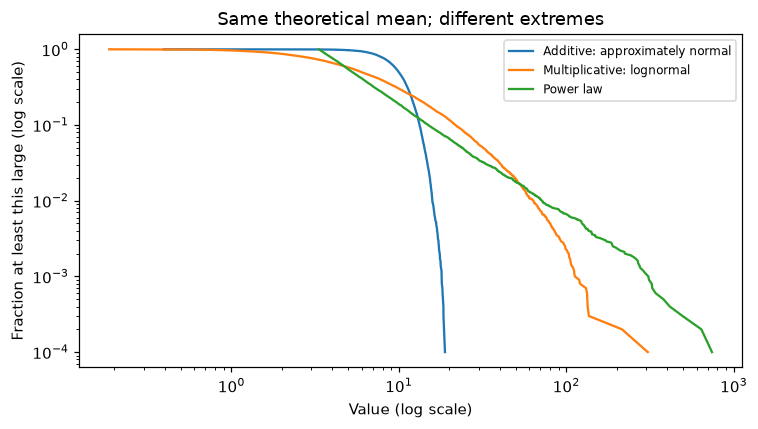

In [3]:
# Show the tails, including the values beyond the histograms.
fig, ax = plt.subplots(figsize=(7, 4))
for name, values in patterns.items():
    ordered = np.sort(values)
    fraction_at_least = (len(ordered) - np.arange(len(ordered))) / len(ordered)
    positive = ordered > 0
    ax.loglog(ordered[positive], fraction_at_least[positive], label=name)
ax.set(xlabel='Value (log scale)', ylabel='Fraction at least this large (log scale)',
       title='Same theoretical mean; different extremes')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


**Notice:** Which sample has a mean furthest from its median? A power-law tail is approximately straight on log-log axes; that alone is not a statistical test.

### Central limit theorem and sample size
The **averages** become approximately normal—not the original observations. Here the draws are independent and have finite variance.

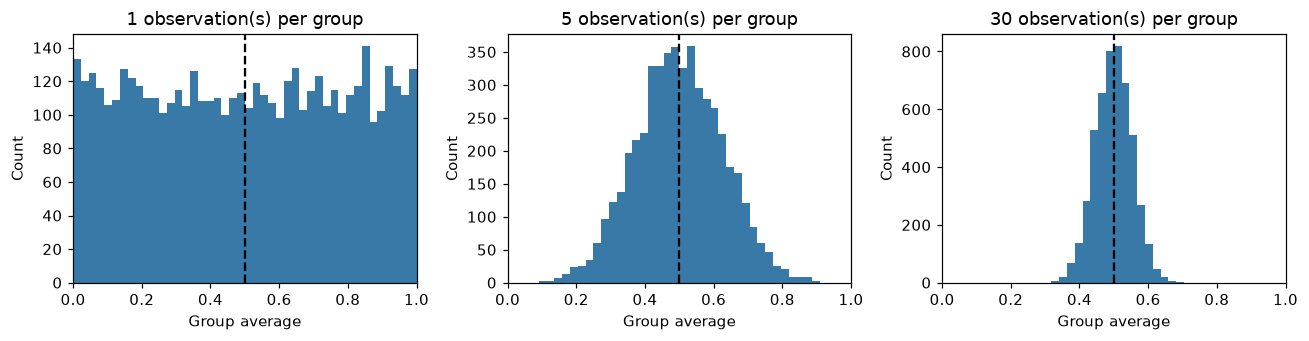

In [4]:
group_sizes = [1, 5, 30]
number_of_groups = 5000
rng = np.random.default_rng(43)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, n in zip(axes, group_sizes):
    averages = rng.uniform(0, 1, (number_of_groups, n)).mean(axis=1)
    ax.hist(averages, bins=np.linspace(0, 1, 45), color='#3979a8')
    ax.axvline(.5, color='black', linestyle='--')
    ax.set(title=f'{n} observation(s) per group', xlim=(0, 1), xlabel='Group average', ylabel='Count')
fig.tight_layout()
plt.show()


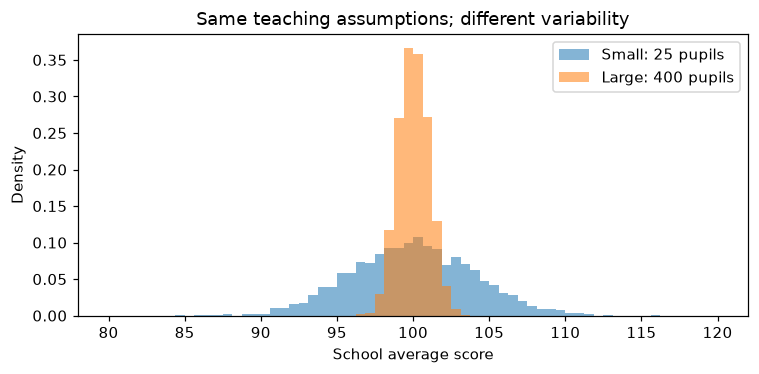

In [5]:
# Schools have the same underlying score distribution; only size differs.
small_school = 25
large_school = 400
schools_per_size = 3000
rng = np.random.default_rng(44)
fig, ax = plt.subplots(figsize=(7, 3.5))
rows = []
for label, n in [('Small', small_school), ('Large', large_school)]:
    means = rng.normal(100, 20, (schools_per_size, n)).mean(axis=1)
    ax.hist(means, bins=np.linspace(80, 120, 65), density=True, alpha=.55, label=f'{label}: {n} pupils')
    rows.append({'School': label, 'Observed spread of school averages': means.std(),
                 'Expected spread: 20 / sqrt(n)': 20 / np.sqrt(n)})
ax.set(xlabel='School average score', ylabel='Density', title='Same teaching assumptions; different variability')
ax.legend(); fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(2))


**Explain:** Why can small schools appear at both extremes?

## 2. Complexity: fit versus prediction
**Bias:** systematic mismatch. **Variance:** how much the fitted model changes across training samples. We redraw noisy outcomes at the same training locations; the underlying relationship stays fixed.

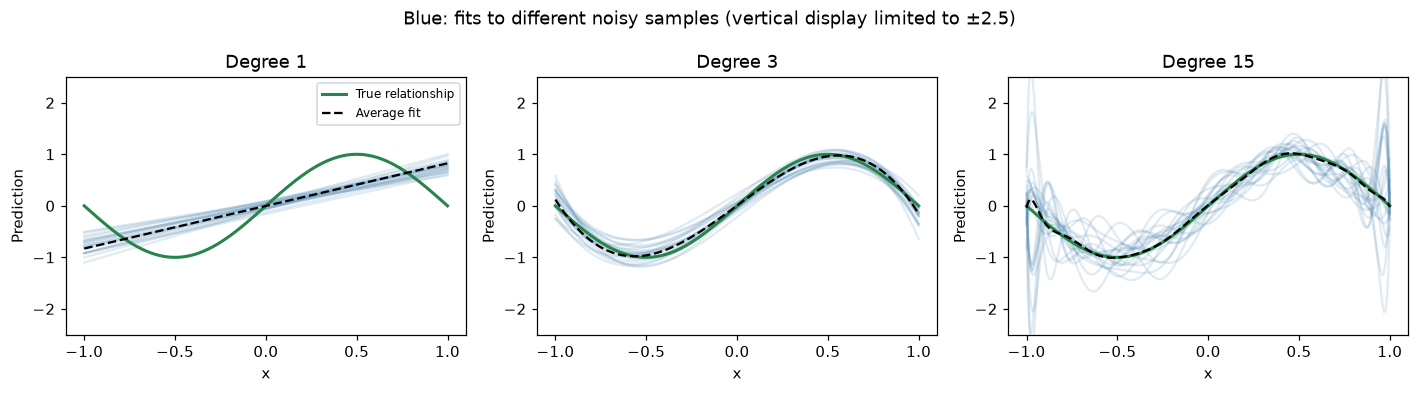

In [6]:
degrees = [1, 3, 15]
training_points = 25
repetitions = 100
noise_sd = .35
if training_points <= max(degrees) or repetitions < 2 or noise_sd < 0:
    raise ValueError('Use more training points than the largest degree, at least 2 repetitions, and nonnegative noise.')
rng = np.random.default_rng(45)
x_train = np.linspace(-1, 1, training_points)
x_test = np.linspace(-1, 1, 250)
truth = lambda x: np.sin(np.pi * x)
predictions = {d: [] for d in degrees}
train_errors = {d: [] for d in degrees}
# Each degree receives exactly the same training outcomes in each repetition.
for _ in range(repetitions):
    y_train = truth(x_train) + rng.normal(0, noise_sd, training_points)
    for degree in degrees:
        fitted = Polynomial.fit(x_train, y_train, degree)
        predictions[degree].append(fitted(x_test))
        train_errors[degree].append(np.mean((fitted(x_train) - y_train)**2))
fig, axes = plt.subplots(1, len(degrees), figsize=(13, 3.6), squeeze=False)
rows = []
for ax, degree in zip(axes[0], degrees):
    curves = np.asarray(predictions[degree])
    average = curves.mean(axis=0)
    bias_squared = np.mean((average - truth(x_test))**2)
    variance = np.mean(np.var(curves, axis=0))
    for curve in curves[:20]: ax.plot(x_test, curve, color='#3979a8', alpha=.15)
    ax.plot(x_test, truth(x_test), color='#27844a', lw=2, label='True relationship')
    ax.plot(x_test, average, color='black', linestyle='--', label='Average fit')
    ax.set(title=f'Degree {degree}', ylim=(-2.5, 2.5), xlabel='x', ylabel='Prediction')
    rows.append({'Degree': degree, 'Training error': np.mean(train_errors[degree]),
                 'Squared bias': bias_squared, 'Variance': variance,
                 'Expected new-data error (estimated)': bias_squared + variance + noise_sd**2})
axes[0, 0].legend(fontsize=8)
fig.suptitle('Blue: fits to different noisy samples (vertical display limited to ±2.5)')
fig.tight_layout(); plt.show()
complexity_results = pd.DataFrame(rows)
display(complexity_results.round(4))


**Notice:** Low training error need not mean low new-data error. For squared error, expected prediction error separates into **squared bias + variance + irreducible noise**. Values above are finite-run estimates.

## 3. One judgment versus many
### Condorcet: majority votes
With independent voters of equal accuracy **above 50%**, a larger odd-numbered jury becomes more likely to choose correctly. “Wisdom of crowds” is the broader idea.

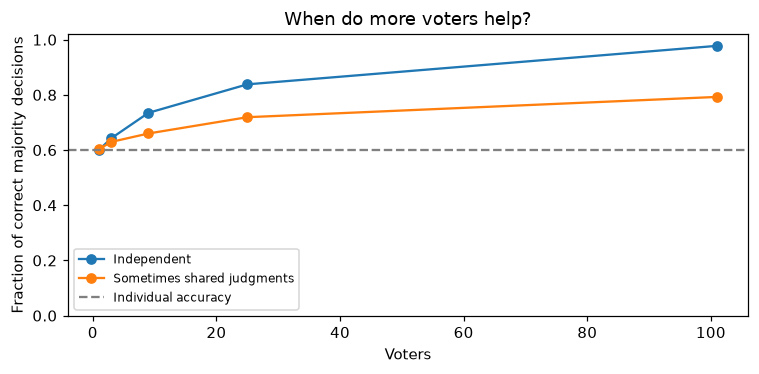

In [7]:
voter_accuracy = .60  # Try .50 or .40.
shared_error_fraction = .50  # On this fraction of trials, all voters make the same judgment.
trials = 10000
jury_sizes = [1, 3, 9, 25, 101]
if not (0 <= voter_accuracy <= 1 and 0 <= shared_error_fraction <= 1):
    raise ValueError('Probabilities must be between 0 and 1.')
rng = np.random.default_rng(46)
rows = []
for n in jury_sizes:
    votes = rng.random((trials, n)) < voter_accuracy
    independent_correct = (votes.sum(axis=1) > n / 2).mean()
    shared_trials = rng.random(trials) < shared_error_fraction
    common_judgment = rng.random(trials) < voter_accuracy
    dependent_votes = votes.copy()
    dependent_votes[shared_trials, :] = common_judgment[shared_trials, None]
    rows.append({'Voters': n, 'Independent': independent_correct,
                 'Sometimes shared judgments': (dependent_votes.sum(axis=1) > n / 2).mean()})
jury_results = pd.DataFrame(rows)
ax = jury_results.plot(x='Voters', y=['Independent', 'Sometimes shared judgments'], marker='o', figsize=(7, 3.5))
ax.axhline(voter_accuracy, color='gray', linestyle='--', label='Individual accuracy')
ax.set(ylim=(0, 1.02), ylabel='Fraction of correct majority decisions', title='When do more voters help?')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


### Diversity prediction theorem: numerical estimates
For an equally weighted average and squared error: **crowd error = average individual error − diversity**. Diversity is squared disagreement around the crowd estimate. It is an identity, not a guarantee that arbitrary disagreement improves forecasts.

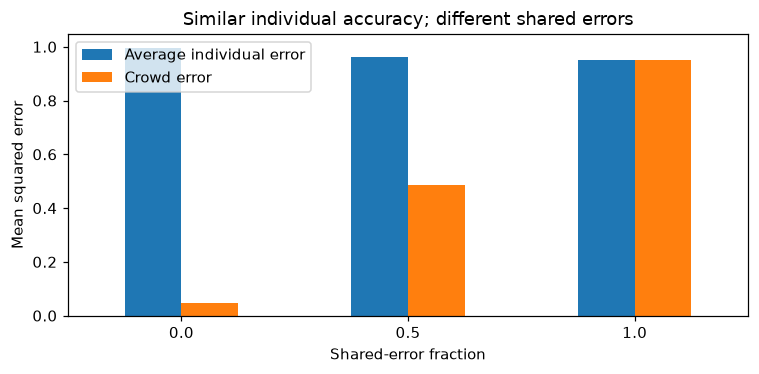

In [8]:
individual_error_sd = 1.0
forecasters = 20
cases = 2000
if individual_error_sd <= 0 or forecasters < 2 or cases < 2:
    raise ValueError('Use positive error size, at least 2 forecasters, and at least 2 cases.')
rng = np.random.default_rng(47)
common_noise = rng.normal(size=(cases, 1))
separate_noise = rng.normal(size=(cases, forecasters))
actual = rng.normal(size=(cases, 1))
rows = []
for shared_fraction in [0, .5, 1]:
    errors = individual_error_sd * (np.sqrt(shared_fraction)*common_noise
                                 + np.sqrt(1-shared_fraction)*separate_noise)
    forecasts = actual + errors
    crowd = forecasts.mean(axis=1, keepdims=True)
    individual_mse = np.mean((forecasts - actual)**2)
    crowd_mse = np.mean((crowd - actual)**2)
    diversity = np.mean((forecasts - crowd)**2)
    assert np.isclose(crowd_mse, individual_mse - diversity)
    rows.append({'Shared-error fraction': shared_fraction,
                 'Average individual error': individual_mse, 'Diversity': diversity,
                 'Crowd error': crowd_mse})
ensemble_results = pd.DataFrame(rows)
display(ensemble_results.round(4))
ax = ensemble_results.plot(x='Shared-error fraction', y=['Average individual error', 'Crowd error'],
                          kind='bar', figsize=(7, 3.5), rot=0)
ax.set(ylabel='Mean squared error', title='Similar individual accuracy; different shared errors')
plt.tight_layout(); plt.show()


**Connect:** Why might three sentiment models with different methods add more than three very similar models? Agreement does not by itself prove correctness.

## 4. The paradox of skill
Keep luck fixed; narrow differences in skill. Luck can explain more of the variation **among elite competitors**, even though reaching that level requires great skill.

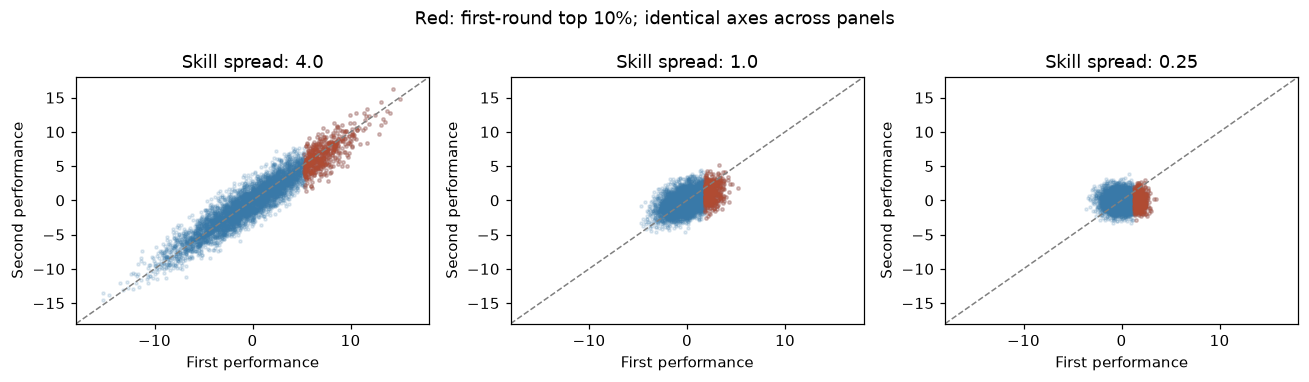

In [9]:
luck_sd = 1.0
skill_spreads = [4.0, 1.0, .25]
competitors = 5000
rng = np.random.default_rng(48)
base_skill = rng.normal(size=competitors)
first_luck = rng.normal(0, luck_sd, competitors)
second_luck = rng.normal(0, luck_sd, competitors)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
rows = []
for ax, spread in zip(axes, skill_spreads):
    skill = spread * base_skill
    first = skill + first_luck
    second = skill + second_luck
    top = first >= np.quantile(first, .9)
    ax.scatter(first, second, s=4, alpha=.15, color='#3979a8')
    ax.scatter(first[top], second[top], s=5, alpha=.25, color='#b34b32')
    ax.set(title=f'Skill spread: {spread}', xlabel='First performance', ylabel='Second performance',
           xlim=(-18, 18), ylim=(-18, 18))
    ax.plot([-18, 18], [-18, 18], color='gray', linestyle='--', lw=1)
    rows.append({'Skill spread': spread,
                 'Luck share of outcome variance (theory)': luck_sd**2 / (spread**2 + luck_sd**2),
                 'Top 10%: first mean': first[top].mean(),
                 'Same people: second mean': second[top].mean()})
fig.suptitle('Red: first-round top 10%; identical axes across panels')
fig.tight_layout(); plt.show()
skill_results = pd.DataFrame(rows)
display(skill_results.round(3))


**Explain:** Why do first-round stars often move closer to the average next time? Their skill did not change.

**Discuss with the reading:** prediction ≠ causation; the Matthew effect reinforces advantage; self-organized criticality builds pressure and releases it in cascades. These mechanisms are not interchangeable.